In [218]:
# !pip install sentence-transformers scikit-learn pandas seaborn matplotlib

In [219]:
# Cell 2 — Imports
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime, timezone
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
import warnings
warnings.filterwarnings("ignore")

In [220]:
# Cell 3 — Config
VIDEO_IDS        = [25, 26, 27, 28]
ANNOTATIONS_DIR  = Path("..", "Moment-Retrieval-and-Video-Summarization", "Annotations")
DESCRIPTIONS_DIR = Path("..", "Moment-Retrieval-and-Video-Summarization", "Descriptions")
EVAL_DIR         = Path("..", "Moment-Retrieval-and-Video-Summarization", "Evaluations")
EVAL_DIR.mkdir(parents=True, exist_ok=True)

# ── Choose your combo here ────────────────────────────────────────
VLM_PROMPT_TYPE  = "short"   # "short" | "medium" | "long"
VLM_FRAME_COUNT  = 50       # e.g. 30 | 50 | 100
LLM_PROMPT_TYPE  = "concise"  # "concise" | "detailed"

THRESHOLD = 0.5

In [221]:
# Cell 4 — Load embedder
embedder = SentenceTransformer("all-MiniLM-L6-v2")
print("Embedder loaded!")

Embedder loaded!


In [222]:
# Cell 5 — Loaders

def load_human_annotations(video_id):
    """Load handwritten annotations from TXT."""
    txt_file = ANNOTATIONS_DIR / f"video_{video_id}.txt"
    if not txt_file.exists():
        print(f"  Warning: no annotation file found at {txt_file}")
        return []

    with open(txt_file, "r", encoding="utf-8") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    if lines and lines[0].lower().startswith("annotation"):
        lines = lines[1:]

    return lines


def load_generated_events(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    """Load parsed LLM events matching the exact VLM + LLM combo from the video JSON."""
    json_file = DESCRIPTIONS_DIR / f"video_{video_id}.json"
    if not json_file.exists():
        print(f"  Warning: no JSON found for video_{video_id}")
        return []

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    def matches_combo(result):
        result_llm_prompt_type = result.get("prompt_type", result.get("llm_prompt_type"))
        result_vlm_prompt_type = result.get("vlm_source", result.get("vlm_prompt_type"))
        result_vlm_frame_count = result.get("vlm_frame_count", result.get("num_frames"))
        return (
            result_llm_prompt_type == llm_prompt_type
            and result_vlm_prompt_type == vlm_prompt_type
            and result_vlm_frame_count == vlm_frame_count
        )

    result = next(
        (r for r in data.get("llm_results", []) if matches_combo(r)),
        None
    )

    if result is None:
        print(
            f"  Warning: no match for combo "
            f"(vlm={vlm_prompt_type}, frames={vlm_frame_count}, llm={llm_prompt_type}) "
            f"in video_{video_id}"
        )
        return []

    return result.get("parsed_events", [])


def make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    """Unique string key for a combo — used for skip checking."""
    return f"vlm={vlm_prompt_type}__frames={vlm_frame_count}__llm={llm_prompt_type}"


def already_evaluated(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    """Check if this exact combo was already saved."""
    eval_file = EVAL_DIR / f"video_{video_id}_eval.json"
    if not eval_file.exists():
        return False
    with open(eval_file, "r", encoding="utf-8") as f:
        data = json.load(f)
    key = make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type)
    return any(r["combo_key"] == key for r in data.get("evaluations", []))

In [223]:
# Cell 6 — Evaluation logic

def evaluate(human_annotations, generated_events, threshold=THRESHOLD):
    """Compare human annotations vs generated events using cosine similarity."""
    if not human_annotations or not generated_events:
        return None

    human_emb     = embedder.encode(human_annotations)
    generated_emb = embedder.encode(generated_events)
    sim_matrix    = cosine_similarity(human_emb, generated_emb)

    per_annotation = []
    detected = 0
    for i, human_event in enumerate(human_annotations):
        best_score     = float(sim_matrix[i].max())
        best_match_idx = int(sim_matrix[i].argmax())
        best_match     = generated_events[best_match_idx]
        is_detected    = best_score >= threshold

        if is_detected:
            detected += 1

        per_annotation.append({
            "human_event": human_event,
            "best_match":  best_match,
            "score":       round(best_score, 4),
            "detected":    is_detected,
        })

    return {
        "per_annotation":      per_annotation,
        "similarity_matrix":   sim_matrix.tolist(),
        "num_human":           len(human_annotations),
        "num_generated":       len(generated_events),
        "detected":            detected,
        "missed":              len(human_annotations) - detected,
        "recall":              round(detected / len(human_annotations), 4),
        "avg_best_similarity": round(float(sim_matrix.max(axis=1).mean()), 4),
        "threshold":           threshold,
    }

In [224]:
# Cell 7 — Save results

def save_eval_result(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type,
                     eval_result, human_annotations, generated_events):
    eval_file = EVAL_DIR / f"video_{video_id}_eval.json"

    if eval_file.exists():
        with open(eval_file, "r", encoding="utf-8") as f:
            data = json.load(f)
    else:
        data = {"video_id": video_id, "evaluations": []}

    data["evaluations"].append({
        "combo_key":         make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type),
        "vlm_prompt_type":   vlm_prompt_type,
        "vlm_frame_count":   vlm_frame_count,
        "llm_prompt_type":   llm_prompt_type,
        "timestamp":         datetime.now(timezone.utc).isoformat(),
        "threshold":         eval_result["threshold"],
        "human_annotations": human_annotations,
        "generated_events":  generated_events,
        "metrics": {
            "num_human":           eval_result["num_human"],
            "num_generated":       eval_result["num_generated"],
            "detected":            eval_result["detected"],
            "missed":              eval_result["missed"],
            "recall":              eval_result["recall"],
            "avg_best_similarity": eval_result["avg_best_similarity"],
        },
        "per_annotation":    eval_result["per_annotation"],
        "similarity_matrix": eval_result["similarity_matrix"],
    })

    with open(eval_file, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    print(f"  Saved: {eval_file}")

In [225]:
# Cell 8 — Pipeline

for video_id in VIDEO_IDS:
    print(f"\n -> Evaluating video_{video_id} "
          f"(vlm={VLM_PROMPT_TYPE}, frames={VLM_FRAME_COUNT}, llm={LLM_PROMPT_TYPE})...")

    if already_evaluated(video_id, VLM_PROMPT_TYPE, VLM_FRAME_COUNT, LLM_PROMPT_TYPE):
        print(f"  Skipping — already evaluated")
        continue

    human_annotations = load_human_annotations(video_id)
    if not human_annotations:
        print(f"  Skipping — no human annotations found")
        continue

    generated_events = load_generated_events(
        video_id, VLM_PROMPT_TYPE, VLM_FRAME_COUNT, LLM_PROMPT_TYPE
    )
    if not generated_events:
        continue

    result = evaluate(human_annotations, generated_events)
    save_eval_result(
        video_id, VLM_PROMPT_TYPE, VLM_FRAME_COUNT, LLM_PROMPT_TYPE,
        result, human_annotations, generated_events
    )
    print(f"  Recall: {result['recall']:.1%} | Avg similarity: {result['avg_best_similarity']:.2f}")

print("\n\nAll evaluations done!")


 -> Evaluating video_25 (vlm=short, frames=50, llm=concise)...

 -> Evaluating video_26 (vlm=short, frames=50, llm=concise)...

 -> Evaluating video_27 (vlm=short, frames=50, llm=concise)...

 -> Evaluating video_28 (vlm=short, frames=50, llm=concise)...


All evaluations done!


In [226]:
# Cell 9 — Print report

def print_report(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    eval_file = EVAL_DIR / f"video_{video_id}_eval.json"
    if not eval_file.exists():
        # initialise the eval file with empty evaluations list to avoid "Combo not found" error
        with open(eval_file, "w", encoding="utf-8") as f:
            json.dump({"video_id": video_id, "evaluations": []}, f, indent=2)

    with open(eval_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    key = make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type)
    result = next((e for e in data["evaluations"] if e["combo_key"] == key), None)
    if not result:
        print(f"Combo not found: {key}")
        return

    m = result["metrics"]
    print(f"=== video_{video_id} | vlm={vlm_prompt_type} | "
          f"frames={vlm_frame_count} | llm={llm_prompt_type} ===\n")
    print(f"Human annotations : {m['num_human']}")
    print(f"Generated events  : {m['num_generated']}")
    print(f"Detected          : {m['detected']} / {m['num_human']}")
    print(f"Missed            : {m['missed']} / {m['num_human']}")
    print(f"Recall            : {m['recall']:.1%}")
    print(f"Avg similarity    : {m['avg_best_similarity']:.2f}\n")
    print("--- Per annotation ---")
    for item in result["per_annotation"]:
        status = "✅" if item["detected"] else "❌"
        print(f"{status} ({item['score']:.2f}) {item['human_event']}")
        print(f"       → {item['best_match']}\n")

# Make sure pipeline has run first (Cell 8), then call:
print_report(25, VLM_PROMPT_TYPE, VLM_FRAME_COUNT, LLM_PROMPT_TYPE)

Combo not found: vlm=short__frames=50__llm=concise


In [227]:
# Cell 10 — Heatmap

def plot_heatmap(video_id, vlm_prompt_type, vlm_frame_count, llm_prompt_type):
    eval_file = EVAL_DIR / f"video_{video_id}_eval.json"
    if not eval_file.exists():
        print("No eval file found")
        return

    with open(eval_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    key = make_combo_key(vlm_prompt_type, vlm_frame_count, llm_prompt_type)
    result = next((e for e in data["evaluations"] if e["combo_key"] == key), None)
    if not result:
        print(f"Combo not found: {key}")
        return

    sim_matrix       = np.array(result["similarity_matrix"])
    human_labels     = [f"H{i+1}" for i in range(len(result["human_annotations"]))]
    generated_labels = [f"G{i+1}" for i in range(len(result["generated_events"]))]

    plt.figure(figsize=(max(8, len(generated_labels) * 1.2), max(5, len(human_labels) * 0.8)))
    sns.heatmap(
        sim_matrix,
        xticklabels=generated_labels,
        yticklabels=human_labels,
        annot=True, fmt=".2f",
        cmap="YlGnBu", vmin=0, vmax=1
    )
    plt.title(f"video_{video_id} | vlm={vlm_prompt_type} | "
              f"frames={vlm_frame_count} | llm={llm_prompt_type}")
    plt.xlabel("Generated Events")
    plt.ylabel("Human Annotations")
    plt.tight_layout()
    plt.show()

    print("Human annotations:")
    for i, a in enumerate(result["human_annotations"], 1):
        print(f"  H{i}: {a}")
    print("\nGenerated events:")
    for i, e in enumerate(result["generated_events"], 1):
        print(f"  G{i}: {e}")

plot_heatmap(25, VLM_PROMPT_TYPE, VLM_FRAME_COUNT, LLM_PROMPT_TYPE)

Combo not found: vlm=short__frames=50__llm=concise


In [228]:
# Cell 11 — Load all evaluated combos across all videos into a flat dataframe

def load_all_evals(video_ids, eval_dir):
    """Read all eval JSONs and flatten into a dataframe, one row per combo per video."""
    rows = []
    for video_id in video_ids:
        eval_file = eval_dir / f"video_{video_id}_eval.json"
        if not eval_file.exists():
            continue
        with open(eval_file, "r", encoding="utf-8") as f:
            data = json.load(f)
        for e in data.get("evaluations", []):
            m = e["metrics"]
            rows.append({
                "video_id":        video_id,
                "vlm_prompt_type": e["vlm_prompt_type"],
                "vlm_frame_count": e["vlm_frame_count"],
                "llm_prompt_type": e["llm_prompt_type"],
                "combo_key":       e["combo_key"],
                "timestamp":       e["timestamp"],
                "recall":          m["recall"],
                "avg_similarity":  m["avg_best_similarity"],
                "detected":        m["detected"],
                "missed":          m["missed"],
                "num_human":       m["num_human"],
                "num_generated":   m["num_generated"],
            })
    return pd.DataFrame(rows)

df = load_all_evals(VIDEO_IDS, EVAL_DIR)
print(f"Loaded {len(df)} evaluations across {df['video_id'].nunique()} video(s)\n")
print(df[["video_id", "vlm_prompt_type", "vlm_frame_count", "llm_prompt_type", "recall", "avg_similarity"]].to_string(index=False))

Loaded 24 evaluations across 4 video(s)

 video_id vlm_prompt_type  vlm_frame_count llm_prompt_type  recall  avg_similarity
       25            long               30        detailed  0.1818          0.3168
       25            long               30         concise  0.0909          0.2935
       25          medium               30         concise  0.0909          0.3625
       25          medium               30        detailed  0.1818          0.3970
       25           short               30        detailed  0.1818          0.3571
       25           short               30         concise  0.0909          0.3786
       26            long               30        detailed  0.2222          0.4018
       26            long               30         concise  0.3333          0.4093
       26          medium               30         concise  0.2222          0.3675
       26          medium               30        detailed  0.2222          0.3617
       26           short               30    

In [229]:
# Cell 12 — What combos have been RUN (in descriptions JSON) vs EVALUATED

def get_run_combos(video_ids, descriptions_dir):
    """All (vlm, frames, llm) combos that have been run and have parsed_events."""
    rows = []
    for video_id in video_ids:
        json_file = descriptions_dir / f"video_{video_id}.json"
        if not json_file.exists():
            continue
        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)
        for r in data.get("llm_results", []):
            if r.get("parsed_events"):
                rows.append({
                    "video_id":        video_id,
                    "vlm_prompt_type": r.get("vlm_source"),
                    "vlm_frame_count": r.get("vlm_frame_count"),
                    "llm_prompt_type": r.get("prompt_type"),
                    "n_events":        len(r["parsed_events"]),
                })
    return pd.DataFrame(rows)

run_df  = get_run_combos(VIDEO_IDS, DESCRIPTIONS_DIR)
eval_keys = set(df["combo_key"]) if not df.empty else set()

def make_key(row):
    return f"vlm={row['vlm_prompt_type']}__frames={row['vlm_frame_count']}__llm={row['llm_prompt_type']}"

run_df["combo_key"]  = run_df.apply(make_key, axis=1)
run_df["evaluated"]  = run_df["combo_key"].isin(eval_keys)

print("=== Combos run vs evaluated ===\n")
print(run_df[["video_id", "vlm_prompt_type", "vlm_frame_count",
              "llm_prompt_type", "n_events", "evaluated"]].to_string(index=False))

not_yet = run_df[~run_df["evaluated"]]
if not not_yet.empty:
    print(f"\n⚠️  {len(not_yet)} combo(s) run but not yet evaluated:")
    print(not_yet[["video_id", "vlm_prompt_type", "vlm_frame_count", "llm_prompt_type"]].to_string(index=False))
else:
    print("\n✅ All run combos have been evaluated!")

=== Combos run vs evaluated ===

 video_id vlm_prompt_type  vlm_frame_count llm_prompt_type  n_events  evaluated
       25            long               30         concise         6       True
       25            long               30        detailed         6       True
       25          medium               30         concise        10       True
       25          medium               30        detailed        10       True
       25           short               30         concise        10       True
       25           short               30        detailed         9       True
       25           short               30         concise        10       True
       25           short               30        detailed        10       True
       25           short               30         concise         6       True
       25           short               30        detailed         5       True
       25           short               30         concise        10       True
       

In [230]:
# Cell 12b — Full status overview: what has been VLM-ed, LLM-ed, and evaluated per video

def get_vlm_runs(video_ids, descriptions_dir):
    """All VLM runs (prompt_type, num_frames) per video."""
    rows = []
    for video_id in video_ids:
        json_file = descriptions_dir / f"video_{video_id}.json"
        if not json_file.exists():
            rows.append({"video_id": video_id, "stage": "VLM", "status": "❌ not run", 
                         "detail": ""})
            continue
        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)
        vlm_results = data.get("vlm_results", [])
        if not vlm_results:
            rows.append({"video_id": video_id, "stage": "VLM", "status": "❌ not run",
                         "detail": ""})
        for r in vlm_results:
            rows.append({
                "video_id": video_id,
                "stage":    "VLM",
                "status":   "✅ done",
                "detail":   f"prompt={r['prompt_type']} | frames={r['num_frames']} | "
                            f"{len(r['response'].split())} words"
            })
    return rows

def get_llm_runs(video_ids, descriptions_dir):
    """All LLM runs (vlm_source, vlm_frame_count, prompt_type) per video."""
    rows = []
    for video_id in video_ids:
        json_file = descriptions_dir / f"video_{video_id}.json"
        if not json_file.exists():
            continue
        with open(json_file, "r", encoding="utf-8") as f:
            data = json.load(f)
        llm_results = data.get("llm_results", [])
        if not llm_results:
            rows.append({"video_id": video_id, "stage": "LLM", "status": "❌ not run",
                         "detail": ""})
        for r in llm_results:
            n_events = len(r.get("parsed_events", []))
            rows.append({
                "video_id": video_id,
                "stage":    "LLM",
                "status":   "✅ done",
                "detail":   f"llm={r['prompt_type']} | vlm={r.get('vlm_source')} | "
                            f"frames={r.get('vlm_frame_count')} | {n_events} events parsed"
            })
    return rows

def get_eval_runs(video_ids, eval_dir):
    """All evaluation runs per video."""
    rows = []
    for video_id in video_ids:
        eval_file = eval_dir / f"video_{video_id}_eval.json"
        if not eval_file.exists():
            rows.append({"video_id": video_id, "stage": "EVAL", "status": "❌ not run",
                         "detail": ""})
            continue
        with open(eval_file, "r", encoding="utf-8") as f:
            data = json.load(f)
        evals = data.get("evaluations", [])
        if not evals:
            rows.append({"video_id": video_id, "stage": "EVAL", "status": "❌ not run",
                         "detail": ""})
        for e in evals:
            m = e["metrics"]
            rows.append({
                "video_id": video_id,
                "stage":    "EVAL",
                "status":   "✅ done",
                "detail":   f"llm={e['llm_prompt_type']} | vlm={e['vlm_prompt_type']} | "
                            f"frames={e['vlm_frame_count']} | "
                            f"recall={m['recall']:.1%} | sim={m['avg_best_similarity']:.2f}"
            })
    return rows

# ── Build and print the full status table ────────────────────────
all_rows = get_vlm_runs(VIDEO_IDS, DESCRIPTIONS_DIR) + \
           get_llm_runs(VIDEO_IDS, DESCRIPTIONS_DIR) + \
           get_eval_runs(VIDEO_IDS, EVAL_DIR)

status_df = pd.DataFrame(all_rows)

for video_id in VIDEO_IDS:
    print(f"\n{'='*60}")
    print(f"  VIDEO {video_id}")
    print(f"{'='*60}")
    video_df = status_df[status_df["video_id"] == video_id]

    for stage in ["VLM", "LLM", "EVAL"]:
        stage_df = video_df[video_df["stage"] == stage]
        print(f"\n  [{stage}]")
        if stage_df.empty:
            print(f"    ❌ not run")
        else:
            for _, row in stage_df.iterrows():
                print(f"    {row['status']}  {row['detail']}")

# ── Missing combos: VLM runs that have no LLM result yet ─────────
print(f"\n\n{'='*60}")
print("  MISSING: VLM runs with no LLM result")
print(f"{'='*60}")

for video_id in VIDEO_IDS:
    json_file = DESCRIPTIONS_DIR / f"video_{video_id}.json"
    if not json_file.exists():
        continue
    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    vlm_combos = {
        (r["prompt_type"], r["num_frames"])
        for r in data.get("vlm_results", [])
    }
    llm_combos = {
        (r.get("vlm_source"), r.get("vlm_frame_count"))
        for r in data.get("llm_results", [])
    }
    missing_llm = vlm_combos - llm_combos
    if missing_llm:
        print(f"\n  video_{video_id} — VLM runs not yet LLM-ed:")
        for vlm_prompt, frames in sorted(missing_llm):
            print(f"    vlm={vlm_prompt} | frames={frames}")

# ── Missing combos: LLM runs that have no eval yet ───────────────
print(f"\n\n{'='*60}")
print("  MISSING: LLM runs with no evaluation")
print(f"{'='*60}")

eval_keys = set(df["combo_key"]) if not df.empty else set()

for _, row in run_df[~run_df["evaluated"]].iterrows():
    print(f"\n  video_{int(row['video_id'])} — not evaluated: "
          f"vlm={row['vlm_prompt_type']} | frames={row['vlm_frame_count']} | "
          f"llm={row['llm_prompt_type']}")

if run_df[~run_df["evaluated"]].empty:
    print("  ✅ All LLM runs have been evaluated!")


  VIDEO 25

  [VLM]
    ✅ done  prompt=short | frames=30 | 216 words
    ✅ done  prompt=medium | frames=30 | 181 words
    ✅ done  prompt=long | frames=30 | 132 words
    ✅ done  prompt=short | frames=50 | 368 words
    ✅ done  prompt=medium | frames=50 | 93 words
    ✅ done  prompt=long | frames=50 | 224 words

  [LLM]
    ✅ done  llm=concise | vlm=long | frames=30 | 6 events parsed
    ✅ done  llm=detailed | vlm=long | frames=30 | 6 events parsed
    ✅ done  llm=concise | vlm=medium | frames=30 | 10 events parsed
    ✅ done  llm=detailed | vlm=medium | frames=30 | 10 events parsed
    ✅ done  llm=concise | vlm=short | frames=30 | 10 events parsed
    ✅ done  llm=detailed | vlm=short | frames=30 | 9 events parsed
    ✅ done  llm=concise | vlm=short | frames=30 | 10 events parsed
    ✅ done  llm=detailed | vlm=short | frames=30 | 10 events parsed
    ✅ done  llm=concise | vlm=short | frames=30 | 6 events parsed
    ✅ done  llm=detailed | vlm=short | frames=30 | 5 events parsed
    ✅ d

In [231]:
# Cell 13 — Best combos ranked by recall, then avg similarity

if df.empty:
    print("No evaluations found yet — run the pipeline first")
else:
    print("=== Best combos by recall (averaged across videos) ===\n")
    ranked = (
        df.groupby(["vlm_prompt_type", "vlm_frame_count", "llm_prompt_type"])
        .agg(
            avg_recall      =("recall",       "mean"),
            avg_similarity  =("avg_similarity","mean"),
            avg_detected    =("detected",      "mean"),
            avg_missed      =("missed",        "mean"),
            n_videos        =("video_id",      "count"),
        )
        .reset_index()
        .sort_values(["avg_recall", "avg_similarity"], ascending=False)
    )
    ranked.index = range(1, len(ranked) + 1)
    ranked.columns = ["VLM prompt", "Frames", "LLM prompt",
                      "Avg recall", "Avg similarity", "Avg detected",
                      "Avg missed", "# videos"]
    ranked["Avg recall"]     = ranked["Avg recall"].map("{:.1%}".format)
    ranked["Avg similarity"] = ranked["Avg similarity"].map("{:.2f}".format)
    ranked["Avg detected"]   = ranked["Avg detected"].map("{:.1f}".format)
    ranked["Avg missed"]     = ranked["Avg missed"].map("{:.1f}".format)
    print(ranked.to_string())
    print(f"\n🏆 Best combo: VLM={ranked.iloc[0]['VLM prompt']}, "
          f"Frames={ranked.iloc[0]['Frames']}, "
          f"LLM={ranked.iloc[0]['LLM prompt']}")

=== Best combos by recall (averaged across videos) ===

  VLM prompt  Frames LLM prompt Avg recall Avg similarity Avg detected Avg missed  # videos
1       long      30    concise      22.1%           0.37          2.2        9.0         4
2       long      30   detailed      18.8%           0.37          2.0        9.2         4
3      short      30   detailed      17.6%           0.38          2.0        9.2         4
4     medium      30   detailed      14.4%           0.37          1.5        9.8         4
5     medium      30    concise       9.4%           0.36          1.0       10.2         4
6      short      30    concise       8.2%           0.38          1.0       10.2         4

🏆 Best combo: VLM=long, Frames=30, LLM=concise


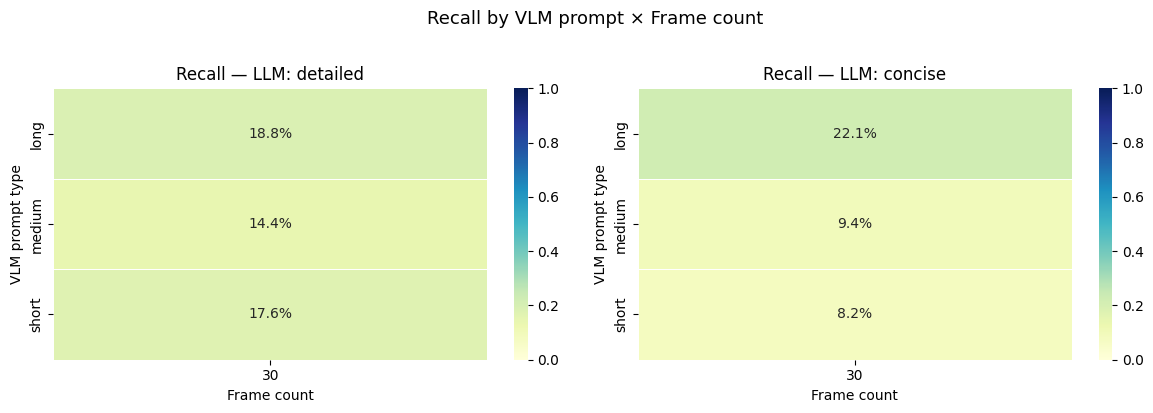

In [232]:
# Cell 14 — Recall heatmap: VLM prompt x Frame count (per LLM prompt type)

if df.empty:
    print("No evaluations found yet")
else:
    llm_types = df["llm_prompt_type"].unique()
    fig, axes = plt.subplots(1, len(llm_types),
                             figsize=(6 * len(llm_types), 4),
                             squeeze=False)

    for ax, llm_type in zip(axes[0], llm_types):
        subset = df[df["llm_prompt_type"] == llm_type]
        pivot  = subset.pivot_table(
            index="vlm_prompt_type",
            columns="vlm_frame_count",
            values="recall",
            aggfunc="mean"
        )
        sns.heatmap(
            pivot, ax=ax,
            annot=True, fmt=".1%",
            cmap="YlGnBu", vmin=0, vmax=1,
            linewidths=0.5
        )
        ax.set_title(f"Recall — LLM: {llm_type}")
        ax.set_xlabel("Frame count")
        ax.set_ylabel("VLM prompt type")

    plt.suptitle("Recall by VLM prompt × Frame count", y=1.02, fontsize=13)
    plt.tight_layout()
    plt.show()

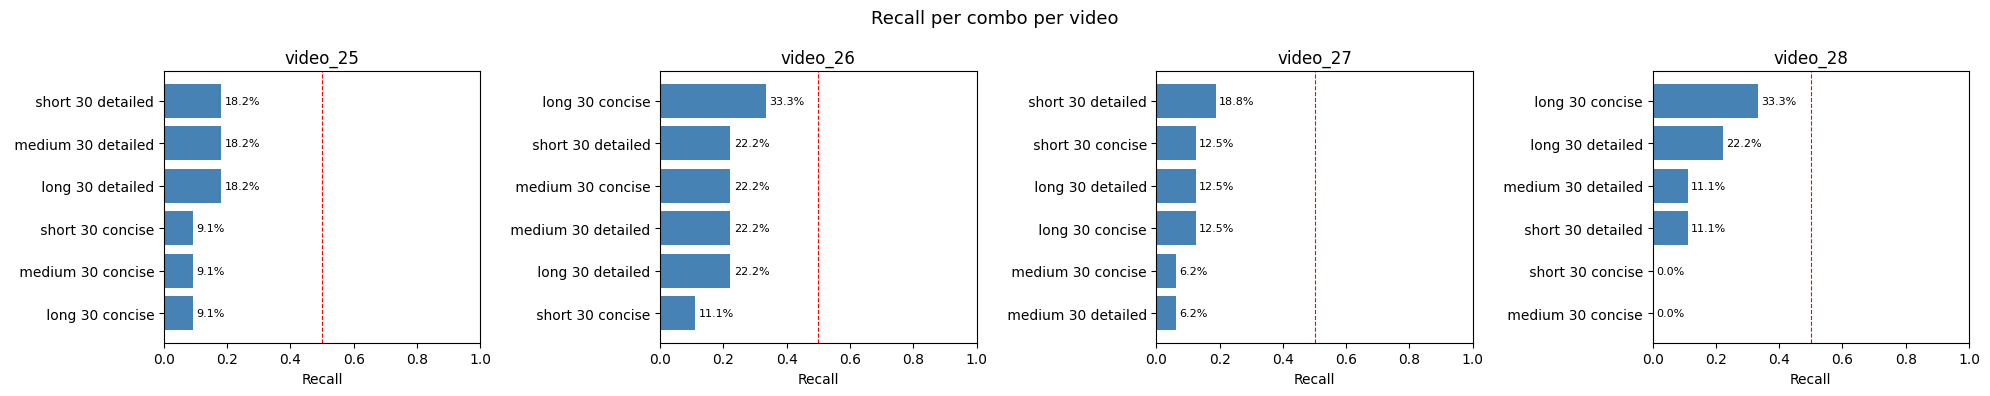

In [233]:
# Cell 15 — Per-video breakdown: who's doing best on each video

if df.empty:
    print("No evaluations found yet")
else:
    fig, axes = plt.subplots(1, len(VIDEO_IDS),
                             figsize=(5 * len(VIDEO_IDS), 4),
                             squeeze=False)

    for ax, video_id in zip(axes[0], VIDEO_IDS):
        subset = df[df["video_id"] == video_id].copy()
        if subset.empty:
            ax.set_title(f"video_{video_id} — no data")
            continue
        subset = subset.sort_values("recall", ascending=True)
        bars = ax.barh(subset["combo_key"].str.replace("vlm=|__llm=|__frames=", " ", regex=True),
                       subset["recall"], color="steelblue")
        ax.set_xlim(0, 1)
        ax.set_xlabel("Recall")
        ax.set_title(f"video_{video_id}")
        ax.axvline(THRESHOLD, color="red", linestyle="--", linewidth=0.8, label=f"threshold={THRESHOLD}")
        for bar, val in zip(bars, subset["recall"]):
            ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height() / 2,
                    f"{val:.1%}", va="center", fontsize=8)

    plt.suptitle("Recall per combo per video", fontsize=13)
    plt.tight_layout()
    plt.show()